# 1ª entrega — Análise Exploratória de Dados (AED) comentada
**Aluno(a):** _Gabriela Marino Koerich_ · **Disciplina:** Python Machine Learning

**Pergunta do projeto:** a partir de biomarcadores, é possível (1) classificar o paciente em `BCG`, `cancer`, `imunodeficiencia` ou `leucemia`, (2) prever o valor de `IFN-γ` e (3) encontrar grupos naturais (clusters)?

**Critério de sucesso:** F1-macro ≥ 0,75 na classificação; R² ≥ 0,70 na regressão.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../dados/biomarcadores.csv")
df.shape

(1000, 38)

## 1. Visão geral

In [4]:
df.head()

,CD34,TdT,MPO,CD19_1,CD20_1,CD22,CD3_1,CD7,BCR-ABL,PML-RARA,...,IgA_2,IgM,CD16,CD56,DHR,CH50,C3,C4,FOXP3,classe
0,0.119362,True,True,0.471228,0.398837,0.233216,0.329756,0.417118,True,True,...,Alto,Alto,247.894093,396.067195,0.967908,93,230,42,Normal,leucemia
1,0.112420,True,True,0.292042,0.370941,0.253135,0.340733,0.350616,True,True,...,Alto,Alto,213.416161,361.036864,0.972741,135,351,64,Normal,leucemia
2,0.175636,True,True,0.372872,0.257518,0.451758,0.487803,0.399385,True,True,...,Alto,Alto,296.635039,244.867766,0.971384,69,238,44,Normal,leucemia
3,0.078518,True,True,0.469943,0.495637,0.351360,0.332752,0.487439,True,True,...,Alto,Alto,564.401375,530.296010,0.962450,90,262,41,Normal,leucemia
4,0.061083,True,True,0.349343,0.381742,0.220939,0.479723,0.453555,True,True,...,Alto,Alto,238.791009,152.442218,0.955740,76,209,46,Normal,leucemia


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 38 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   CD34      1000 non-null   float64
 1   TdT       1000 non-null   bool   
 2   MPO       1000 non-null   bool   
 3   CD19_1    1000 non-null   float64
 4   CD20_1    1000 non-null   float64
 5   CD22      1000 non-null   float64
 6   CD3_1     964 non-null    float64
 7   CD7       1000 non-null   float64
 8   BCR-ABL   1000 non-null   bool   
 9   PML-RARA  1000 non-null   bool   
 10  NMP22     1000 non-null   int64  
 11  BTA       961 non-null    object 
 12  hTERT     954 non-null    object 
 13  uCyt+     963 non-null    object 
 14  FGFR3     945 non-null    object 
 15  TP53      1000 non-null   float64
 16  PPD       904 non-null    float64
 17  IFN-γ     1000 non-null   float64
 18  IL-2      1000 non-null   object 
 19  TNF-α     1000 non-null   object 
 20  Th1       1000 non-null   int64

In [8]:
# Classificação das variáveis por tipo
print(f"Observações: {df.shape[0]} | Variáveis: {df.shape[1]}")
print("\nTipos como o pandas leu:")
print(df.dtypes.value_counts())

# Lógicas = só True/False (ignorando faltantes), mesmo que lidas como object
logicas = [c for c in df.columns if set(df[c].dropna().unique()) <= {True, False}]
numericas = [c for c in df.select_dtypes(include="number").columns if c not in logicas]
categoricas = [c for c in df.columns if c not in logicas + numericas]

lidas_como_object = [c for c in logicas if df[c].dtype == "object"]
print("\nLógicas lidas como 'object' por terem faltantes:", lidas_como_object)

pd.DataFrame(
    {
        "Quantidade": [len(numericas), len(logicas), len(categoricas)],
        "Variáveis": [", ".join(numericas), ", ".join(logicas), ", ".join(categoricas)],
    },
    index=["Numéricas", "Lógicas", "Categóricas"],
)

Observações: 1000 | Variáveis: 38

Tipos como o pandas leu:
float64    17
object     12
int64       5
bool        4
Name: count, dtype: int64

Lógicas lidas como 'object' por terem faltantes: ['BTA', 'hTERT', 'uCyt+']


,Quantidade,Variáveis
Numéricas,22,"CD34, CD19_1, CD20_1, CD22, CD3_1, CD7, NMP22,..."
Lógicas,7,"TdT, MPO, BCR-ABL, PML-RARA, BTA, hTERT, uCyt+"
Categóricas,9,"FGFR3, IL-2, TNF-α, IgG_1, IgA_1, IgA_2, IgM, ..."


✍️ **Comentário 1:** O banco possui 1000 observações e 38 variáveis: 22 numéricas (17 contínuas e 5 inteiras), 7 lógicas e 9 categóricas, sendo classe a variável-alvo, com 4 categorias (BCG, cancer, imunodeficiencia e leucemia). O df.info() identifica apenas 4 variáveis do tipo bool, pois BTA, hTERT e uCyt+ contêm valores faltantes e foram lidas como object; conceitualmente, porém, também são lógicas. As categóricas são, em sua maioria, binárias (alto/baixo ou normal/alterado), o que facilita sua transformação em variáveis dummies para os modelos.

## 2. Valores faltantes e constantes

In [19]:
# Variáveis com faltantes: quantidade e proporção
faltantes = df.isna().sum()
faltantes = faltantes[faltantes > 0].sort_values(ascending=False)

total = df.isna().sum().sum()
linhas = df.isna().any(axis=1).sum()
print(f"Total de células faltantes: {total} ({total / df.size * 100:.1f}% do banco)")
print(f"Pacientes com pelo menos um faltante: {linhas} ({linhas / len(df) * 100:.0f}%)")

pd.DataFrame(
    {"Faltantes": faltantes, "Proporção (%)": (faltantes / len(df) * 100).round(1)}
)

Total de células faltantes: 309 (0.8% do banco)
Pacientes com pelo menos um faltante: 260 (26%)


,Faltantes,Proporção (%)
PPD,96,9.6
FGFR3,55,5.5
hTERT,46,4.6
BTA,39,3.9
uCyt+,37,3.7
CD3_1,36,3.6


In [20]:
# Variáveis constantes: um único valor em todos os pacientes (ignorando faltantes)
constantes = [c for c in df.columns if df[c].nunique(dropna=True) <= 1]

restantes = [c for c in faltantes.index if c not in constantes]
print("Faltantes que ainda precisam de tratamento após remover as constantes:", restantes)

pd.DataFrame(
    {
        "Único valor": [df[c].dropna().unique()[0] for c in constantes],
        "Pacientes com esse valor": [df[c].notna().sum() for c in constantes],
        "Faltantes": [df[c].isna().sum() for c in constantes],
    },
    index=constantes,
)

Faltantes que ainda precisam de tratamento após remover as constantes: ['PPD', 'CD3_1']


,Único valor,Pacientes com esse valor,Faltantes
BTA,False,961,39
hTERT,False,954,46
uCyt+,False,963,37
FGFR3,Normal,945,55


✍️ **Comentário 2:** Seis variáveis apresentam valores faltantes, somando 309 células (0,8% do banco). A mais afetada é PPD, com 96 faltantes, seguida de FGFR3 (55), hTERT (46), BTA (39), uCyt+ (37) e CD3_1 (36). BTA, hTERT, uCyt+ e FGFR3 são constantes: todos os pacientes com valor registrado têm o mesmo resultado (False ou Normal). Variáveis constantes não carregam informação capaz de diferenciar as classes; além disso, aumentam a dimensionalidade e podem causar problemas em etapas como a padronização (desvio padrão zero). Por isso foram removidas. Com essa remoção, restam faltantes apenas em PPD e CD3_1. Em PPD, por ser muito assimétrica, os faltantes foram preenchidos com a média após a transformação logarítmica (PPD_log); nas demais numéricas, usou-se a mediana. Preencher em vez de excluir evita perder 260 pacientes (26% do banco), o que reduziria muito o tamanho da amostra.

## 3. Variável alvo — balanceamento das classes

In [13]:
# Balanceamento da variável alvo
from scipy.stats import chisquare

contagem = df["classe"].value_counts()
proporcao = (contagem / len(df) * 100).round(1)

razao = contagem.max() / contagem.min()
print(f"Classe mais frequente: {contagem.idxmax()} ({contagem.max()} pacientes)")
print(f"Classe menos frequente: {contagem.idxmin()} ({contagem.min()} pacientes)")
print(f"Razão maior/menor: {razao:.2f}")

# Qui-quadrado de aderência: H0 = as 4 classes têm a mesma frequência (25% cada)
estat, p_valor = chisquare(contagem)
print(f"Qui-quadrado de aderência à distribuição uniforme: p = {p_valor:.3f}")

pd.DataFrame({"Pacientes": contagem, "Proporção (%)": proporcao})

Classe mais frequente: cancer (269 pacientes)
Classe menos frequente: leucemia (227 pacientes)
Razão maior/menor: 1.19
Qui-quadrado de aderência à distribuição uniforme: p = 0.192


,Pacientes,Proporção (%)
classe,,
cancer,269,26.9
BCG,264,26.4
imunodeficiencia,240,24.0
leucemia,227,22.7


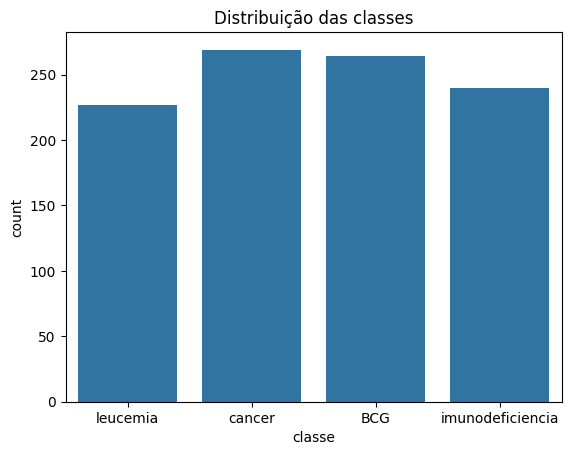

In [14]:
sns.countplot(data=df, x="classe")
plt.title("Distribuição das classes")
plt.show()

In [16]:
# SMOTE (Synthetic Minority Over-sampling Technique)
# -------------------------------------------------
# O que é: técnica de balanceamento que cria observações SINTÉTICAS
#   da classe minoritária (não apenas copia as que já existem).
# Como funciona: para cada paciente da classe minoritária, escolhe um
#   de seus k vizinhos mais próximos (mesma classe) e cria um novo
#   ponto em algum lugar da linha que liga os dois.
# Quando usar: quando uma classe é bem menor que as outras (ex.: 90%
#   x 10%), porque o modelo tende a ignorar a classe rara.
# Cuidado: aplicar SÓ no conjunto de TREINO, depois da divisão.
#   Validação e teste devem continuar com dados reais; senão há
#   vazamento de dados e as métricas ficam otimistas demais.
# Biblioteca: imblearn -> from imblearn.over_sampling import SMOTE
# Neste projeto: NÃO foi necessário, pois as classes já estão
#   balanceadas (razão maior/menor = 1,19; qui-quadrado p = 0,192).
pd.DataFrame({"Pacientes": contagem, "Proporção (%)": proporcao})

,Pacientes,Proporção (%)
classe,,
cancer,269,26.9
BCG,264,26.4
imunodeficiencia,240,24.0
leucemia,227,22.7


✍️ **Comentário 3:** Seguindo o tema de balanceamento da aula 04 (Aquisição dos dados) e o notebook de SMOTE da disciplina, verificou-se se as classes precisariam ser equilibradas. No exemplo da aula, um banco com proporção 90% x 10% foi dividido de forma estratificada e o SMOTE foi aplicado apenas no treino, igualando as classes (630 x 630). No banco de biomarcadores, as quatro classes já estão próximas de 25% cada (de 22,7% a 26,9%), com razão de apenas 1,19 entre a maior e a menor, e o teste qui-quadrado de aderência não rejeita a hipótese de distribuição uniforme (p = 0,192). Portanto, o SMOTE não foi necessário. Da aula, manteve-se a divisão estratificada pela classe, que preserva essas proporções em treino, validação e teste.

✍️ **Comentário 4:** As quatro classes estão bem balanceadas: a mais frequente (cancer, 269 pacientes, 26,9%) tem apenas 1,19 vez o tamanho da menos frequente (leucemia, 227 pacientes, 22,7%), próximo dos 25% esperados para cada uma. O teste qui-quadrado de aderência não rejeita a hipótese de distribuição uniforme entre as classes (p = 0,192). Por isso, não é necessário aplicar SMOTE: essa técnica gera observações sintéticas para compensar classes minoritárias, e aqui nenhuma classe é minoritária. Usá-la sem necessidade adicionaria dados artificiais sem ganho e com risco de sobreajuste. Para manter essas proporções em todas as etapas, a divisão em treino, validação e teste foi feita de forma estratificada pela classe.

In [21]:
# Proporção das classes: divisão estratificada x sorteio simples
import sys
sys.path.append("..")  # permite importar a pasta src a partir de notebooks/
from sklearn.model_selection import train_test_split
from src.dados import estruturar_dados, dividir_dados

df_estr = estruturar_dados(df)

# Estratificada (a usada no projeto)
treino, validacao, teste = dividir_dados(df_estr)

# Sorteio simples, só para comparação
t_s, resto_s = train_test_split(df_estr, test_size=0.30, random_state=42)
v_s, te_s = train_test_split(resto_s, test_size=0.50, random_state=42)

def proporcoes(partes):
    return pd.DataFrame(
        {nome: (d["classe"].value_counts(normalize=True) * 100).round(1)
         for nome, d in partes.items()}
    )

print("Estratificada:")
display(proporcoes({"Banco": df_estr, "Treino": treino, "Validação": validacao, "Teste": teste}))
print("Sorteio simples:")
display(proporcoes({"Treino": t_s, "Validação": v_s, "Teste": te_s}))

Estratificada:


,Banco,Treino,Validação,Teste
classe,,,,
cancer,26.9,26.9,27.3,26.7
BCG,26.4,26.4,26.0,26.7
imunodeficiencia,24.0,24.0,24.0,24.0
leucemia,22.7,22.7,22.7,22.7


Sorteio simples:


,Treino,Validação,Teste
classe,,,
BCG,25.9,25.3,30.0
cancer,28.6,20.7,25.3
imunodeficiencia,23.9,24.0,24.7
leucemia,21.7,30.0,20.0


✍️ **Comentário 5:** A divisão em treino (70%), validação (15%) e teste (15%) foi estratificada pela classe, ou seja, o sorteio foi feito dentro de cada classe para que as três partes mantenham as mesmas proporções do banco completo (ex.: leucemia = 22,7% em todas). Sem estratificação, a validação teria 30,0% de leucemia e o teste 30,0% de BCG, o que distorceria as métricas. Assim, as diferenças de desempenho entre os modelos refletem o próprio modelo, e não um sorteio desigual.

## 4. Medidas resumo e distribuições

In [22]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
CD34,1000.0,0.060034,0.063964,0.000038,0.010408,0.019465,0.112731,0.199757
CD19_1,1000.0,0.243074,0.113677,0.100076,0.146372,0.198089,0.338725,0.498847
CD20_1,1000.0,0.252608,0.120787,0.102262,0.148469,0.198387,0.358607,0.499975
CD22,1000.0,0.252441,0.120602,0.100437,0.150200,0.199057,0.348809,0.499585
CD3_1,964.0,0.296845,0.120873,0.100240,0.187193,0.292676,0.407184,0.498341
CD7,1000.0,0.306717,0.115286,0.101436,0.212423,0.298414,0.401273,0.496797
NMP22,1000.0,5.086000,2.559914,1.000000,3.000000,5.000000,7.000000,9.000000
TP53,1000.0,0.136688,0.069226,0.010049,0.083288,0.149010,0.196692,0.249430
PPD,904.0,41.487249,69.967106,1.011322,4.148214,7.565853,27.341549,248.759379
IFN-γ,1000.0,0.281682,0.160837,0.100193,0.169156,0.232476,0.324549,0.699100


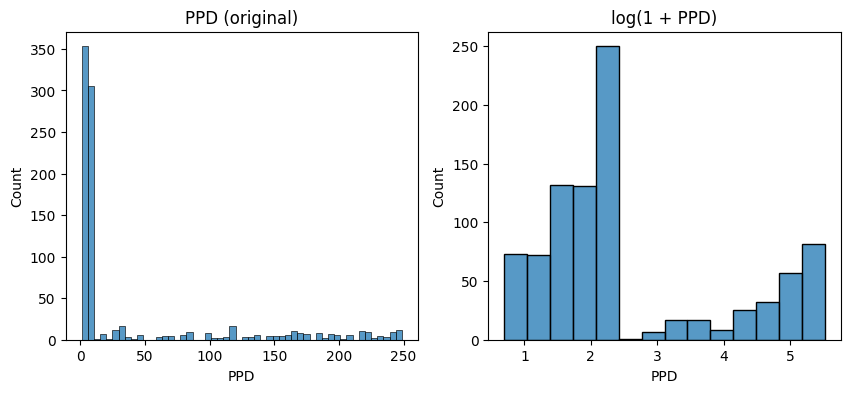

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.histplot(df["PPD"], ax=ax[0]).set_title("PPD (original)")
sns.histplot(np.log1p(df["PPD"]), ax=ax[1]).set_title("log(1 + PPD)")
plt.show()

In [25]:
# GLOSSÁRIO — breve resuminho do que precisa ser lembrado sobre PPD, BCG, IFN-γ e estatísticas descritivas
# ===========================================
# PPD (Purified Protein Derivative / Derivado Proteico Purificado):
#   proteína extraída do Mycobacterium tuberculosis, usada no teste
#   tuberculínico (prova de Mantoux). Uma reação alta indica que o
#   sistema imune já "conhece" a micobactéria, por infecção ou por
#   vacinação. Neste banco, a coluna PPD é a intensidade dessa resposta.
#
# BCG (Bacilo de Calmette-Guérin): vacina contra a tuberculose, feita
#   com uma cepa atenuada de Mycobacterium bovis. Quem recebeu BCG
#   costuma ter resposta ao PPD mais alta, por isso a classe "BCG"
#   concentra os valores altos de PPD.
#
# IFN-γ (interferon gama): citocina produzida por linfócitos T ativados
#   na resposta a micobactérias; também é mais alto no grupo BCG.
#
# Média: soma dos valores dividida pelo número de pacientes. É
#   sensível a valores extremos.
# Mediana: valor do meio quando os dados são ordenados. Não é afetada
#   por valores extremos. Média muito maior que a mediana indica
#   valores altos "puxando" a média.
# Desvio padrão: o quanto os valores se espalham em torno da média.
#
# Assimetria (skewness / skew): mede o quanto a distribuição pende
#   para um lado. 0 = simétrica; entre 0,5 e 1 = moderada;
#   acima de 1 = forte. Positiva = cauda longa à DIREITA, com
#   poucos valores muito altos.
#
# Distribuição bimodal: tem dois "picos", sinal de duas populações
#   misturadas. Aqui: BCG (PPD entre ~10 e 250) e as demais classes
#   (PPD abaixo de 10).
#
# Transformação log(1 + x) — np.log1p: aplica o logaritmo a (x + 1).
#   Comprime os valores grandes muito mais que os pequenos, reduzindo
#   a assimetria. O "+1" evita erro com x = 0, porque log(0) não existe.
#   Ex.: 9 -> 2,3 | 99 -> 4,6 | 249 -> 5,5
#
# Imputação: preencher valores faltantes com uma estimativa (média ou
#   mediana) em vez de excluir o paciente. Na PPD, a média é calculada
#   já na escala log, para não ser inflada pelos valores do BCG.
#
# Algoritmos baseados em distância (k-NN, K-means, SVM): comparam
#   pacientes pela distância entre seus valores. Uma variável com
#   escala muito grande (como PPD até 249) dominaria essa distância,
#   por isso a transformação log e a padronização são importantes.
# PPD antes e depois da transformação log(1 + x)
ppd = df["PPD"].dropna()
ppd_log = np.log1p(ppd)

resumo = pd.DataFrame(
    {
        "PPD (original)": [ppd.mean(), ppd.median(), ppd.std(), ppd.min(), ppd.max(), ppd.skew()],
        "log(1 + PPD)": [ppd_log.mean(), ppd_log.median(), ppd_log.std(), ppd_log.min(), ppd_log.max(), ppd_log.skew()],
    },
    index=["Média", "Mediana", "Desvio padrão", "Mínimo", "Máximo", "Assimetria (skew)"],
).round(2)

print(f"Média / mediana (original): {ppd.mean() / ppd.median():.1f}")
display(resumo)

# De onde vem a cauda longa? PPD por classe
df.groupby("classe")["PPD"].agg(["mean", "median", "max"]).round(1)

Média / mediana (original): 5.5


,PPD (original),log(1 + PPD)
Média,41.49,2.58
Mediana,7.57,2.15
Desvio padrão,69.97,1.42
Mínimo,1.01,0.70
Máximo,248.76,5.52
Assimetria (skew),1.76,0.94


,mean,median,max
classe,,,
BCG,137.6,146.1,248.8
cancer,5.6,5.7,9.9
imunodeficiencia,5.7,5.4,9.9
leucemia,5.3,5.4,9.9


✍️ **Comentário 6:** A PPD apresenta forte assimetria à direita (skew = 1,76): a média (41,5) é 5,5 vezes maior que a mediana (7,6), com valores de 1,0 a 248,8. A análise por classe mostra que essa cauda vem do grupo BCG (mediana 146,1), enquanto as demais classes ficam abaixo de 10, ou seja, a distribuição é bimodal. A transformação log(1 + PPD) comprimiu a escala (0,7 a 5,5) e reduziu a assimetria para 0,94. Com isso, os valores extremos do BCG deixam de dominar algoritmos baseados em distância (k-NN, K-means, SVM) e a imputação dos 96 faltantes pela média fica menos distorcida, pois é feita na escala log (média 2,58) e não na original (média 41,5, inflada pelo BCG). A separação entre o BCG e as demais classes continua visível e torna a PPD_log uma das variáveis mais informativas para os modelos.

✍️ **Comentário 7:** A análise da PPD justifica a transformação adotada na aula 07 (estruturação), em que a variável foi comparada sob diferentes transformações e a logarítmica foi escolhida. A PPD original é fortemente assimétrica (skew = 1,76; média 41,5 contra mediana 7,6), com cauda longa formada pelo grupo BCG. A transformação log reduz a assimetria para 0,94 e permite preencher os 96 faltantes com a média na escala log, sem a distorção dos valores extremos. No projeto, usou-se np.log1p (log(1 + PPD)) em vez do np.log da aula; como a menor PPD é 1,01, o efeito é praticamente o mesmo, mas o log1p evita erro caso algum valor seja zero.

## 5. Variáveis × classe

In [ ]:
for var in ["TP53", "IFN-γ", "CD3_2", "CD8", "CD7"]:
    sns.boxplot(data=df, x="classe", y=var)
    plt.title(var)
    plt.show()

In [ ]:
pd.crosstab(df["FOXP3"], df["classe"], normalize="columns").round(2)

✍️ **Comentário:** quais biomarcadores separam bem as classes? Qual classe se destaca em IFN-γ?

## 6. Correlação

In [ ]:
corr = df.select_dtypes("number").corr(method="spearman")
plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.show()

In [ ]:
# Pares muito correlacionados (|r| > 0,7) -> manter só um de cada par
pares = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
pares[pares.abs() > 0.7].sort_values()

✍️ **Comentário:** CD34, CD19_1, CD20_1, CD22, CD3_1 e CD7 formam um bloco correlacionado. Por que faz sentido manter só uma delas (aqui, CD7)?

## 7. Relatório automático (ydata-profiling)

In [ ]:
from ydata_profiling import ProfileReport

perfil = ProfileReport(df, title="AED - Biomarcadores", explorative=True)
perfil.to_file("relatorio_aed.html")
# perfil.to_notebook_iframe()  # para ver dentro do notebook

## 8. Conclusões da AED
✍️ Resuma em 4–6 tópicos:
- Qualidade dos dados (faltantes, constantes, duplicados) e como tratou;
- Balanceamento das classes;
- Transformações feitas (ex.: `PPD_log`);
- Variáveis selecionadas para os modelos: `TP53, IFN-γ, CD3_2, CD8, PPD_log, CD7, FOXP3`;
- Hipóteses para a modelagem.